# 05c. Atmospheric and land initialization benefits for subseasonal 2-m temperature: gridpoint benefit maps

The gridpoint ACC across the starts of the weekly-mean ensemble mean, per role, and its contrasts, averaged over `map_weeks` (weeks 3-4). With one year and 4 starts per season the gridpoint ACC is very noisy: a secondary diagnostic. Design, inputs and method: `05a`.

**The 05a-05c series** (DART initialization benefits for subseasonal 2-m temperature; each notebook reads the data it needs, computes, saves, then plots): `05a` the three-panel figure on daily running means; `05b` weekly benefits with bootstrap intervals and absolute skill; `05c` gridpoint-ACC benefit maps (DJF, JJA and both seasons in one figure). Settings: `InitBenefitSettings` in `configs/hind_lead_eval_cases.py`; products: `util/init_benefit_workflow.py`; methods: `util/init_benefit.py`.

Every product is saved with the settings it was computed from and read back on the next run when those settings are unchanged; `FORCE_COMPUTE = True` recomputes this notebook's results, `FORCE_INPUTS = True` also re-reads the model output and observations. Model output is read only when a product has to be (re)computed.

## Outputs

`data/hind_lead_eval/init_benefit/init_benefit_maps_<BIAS>_<SET>.nc`; figures `figure/hind_lead_eval/init_benefit/init_benefit_map_<BIAS>.png` (rows: DJF, JJA, both seasons; columns: atmosphere, land benefit).

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options; plain values only, so `papermill -p` overrides work. Case definitions (experiments, regions, windows, options) are the settings defaults; change them for this notebook with `CASE_OVERRIDES`.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction, ELM layer thicknesses
AMIP_ROOT = OBSERVATION_ROOT / "E3SMv3"                        # free-running E3SMv3 DECK AMIP runs
WORKFLOW_NAME = "hind_lead_eval"

CONFIGS = {   # configuration key: raw case name (one case per start: INPUT_DATA_ROOT/<case name>_<YYYYMMDD>00/<ENxx>)
    "CLIM_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE",
    "HYB_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE",
    "DA_ATM": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM",
    "DA_LND": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND",
    "DA_COUPLED": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED",
}
# the experiments of each role are set by the settings (roles); CONFIGS gives their case names

CASE_OVERRIDES = {}     # changes to the InitBenefitSettings defaults (configs/hind_lead_eval_cases.py), e.g. {"max_members": 3}
FORCE_COMPUTE = False    # recompute this notebook's results even when they are saved with the same settings
FORCE_INPUTS = False     # also re-read the model output and observations (slow)


## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import STYLE_MAP, set_case_names
from configs.hind_lead_eval_cases import InitBenefitSettings, RunPaths
from util.hind_case_io import figure_saver, write_dataset, write_table
from util.init_benefit_workflow import InitBenefitCase

paths = RunPaths(*(Path(p) for p in (INPUT_DATA_ROOT, WORK_DIR, DIAGNOSTIC_OUTPUT_ROOT, OBSERVATION_ROOT,
                                     LAND_SUPPORT_DIR, AMIP_ROOT)), workflow_name=WORKFLOW_NAME)
set_case_names(CONFIGS)   # the readers find each configuration's cases by these names
for c, name in CONFIGS.items():
    print(f"[CASE] {c}: {name}_<YYYYMMDD>00")
case = InitBenefitCase(InitBenefitSettings(paths=paths, **{**CASE_OVERRIDES}), force_compute=FORCE_COMPUTE,
                   force_inputs=FORCE_INPUTS)
cfg = case.cfg


[CASE] CLIM_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE_<YYYYMMDD>00
[CASE] HYB_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_<YYYYMMDD>00
[CASE] DA_ATM: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM_<YYYYMMDD>00
[CASE] DA_LND: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND_<YYYYMMDD>00
[CASE] DA_COUPLED: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED_<YYYYMMDD>00
[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit
[MEMBERS] DJF E00: 20: EN01, EN02, EN03, EN04, EN05, EN06, EN07, EN08, EN09, EN10, EN11, EN12, EN13, EN14, EN15, EN16, EN17, EN18, EN19, EN20
[MEMBERS] DJF E10: 20: EN01, EN03, EN04, EN07, EN08, EN09, EN10, EN14, EN17, EN18, EN20, EN21, EN25, EN26, EN28, EN31, EN35, EN36, EN37, EN40
[MEMBERS] DJF E01: 20: EN01, EN03, EN04, EN07, EN08, EN09, EN10, EN14, EN17, EN18, EN20, EN21, EN25, EN26, EN28, EN31, EN35, EN36, EN37, EN40
[MEMBERS] DJ

## 4. Read input

The roles and the seasons in which every role's members are post-processed. The daily member values, observations and climatologies on the region's box (`daily_*.nc`, `daily_ref_*.nc`) are read when the scores must be computed.

In [4]:
display(case.role_table())
print(f"[SEASONS] {case.seasons}; season sets: {case.sets}")

,role,config,atmosphere,land
0,E00,HYB_BASE,ERA5+DART pert.,DATM-forced
1,E10,DA_ATM,DART,DATM-forced
2,E01,DA_LND,ERA5,DART
3,E11,DA_COUPLED,DART,DART


[SEASONS] from the daily caches: ['DJF', 'JJA']
[SEASONS] ['DJF', 'JJA']; season sets: {'DJF': ['DJF'], 'JJA': ['JJA'], 'ALL': ['DJF', 'JJA']}


## 5. Process and save

Gridpoint-ACC contrasts of every week, per bias treatment and season set (`init_benefit_maps_<BIAS>_<SET>.nc`, masked to the region).

In [5]:
maps = {(b, name): case.maps(b, name) for name in case.sets for b in cfg.biases}
print({k: f"{v.attrs['n_starts']} starts" for k, v in maps.items()})

[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit/init_benefit_maps_amip_DJF.nc: built with other settings, recomputing


[DAILY] E00 HYB_BASE DJF: {'init': 4, 'member': 20, 'lead': 56, 'lat': 30, 'lon': 360}


[DAILY] E10 DA_ATM DJF: {'init': 4, 'member': 20, 'lead': 56, 'lat': 30, 'lon': 360}


[DAILY] E01 DA_LND DJF: {'init': 4, 'member': 20, 'lead': 56, 'lat': 30, 'lon': 360}


[DAILY] E11 DA_COUPLED DJF: {'init': 4, 'member': 20, 'lead': 56, 'lat': 30, 'lon': 360}


[DAILY] E00 HYB_BASE JJA: {'init': 4, 'member': 20, 'lead': 56, 'lat': 30, 'lon': 360}


... (6 outputs left out)

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit/init_benefit_maps_amip_JJA.nc
[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit/init_benefit_maps_none_JJA.nc: built with other settings, recomputing


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit/init_benefit_maps_none_JJA.nc
[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit/init_benefit_maps_amip_ALL.nc: built with other settings, recomputing


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit/init_benefit_maps_amip_ALL.nc
[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit/init_benefit_maps_none_ALL.nc: built with other settings, recomputing


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit/init_benefit_maps_none_ALL.nc
{('amip', 'DJF'): '4 starts', ('none', 'DJF'): '4 starts', ('amip', 'JJA'): '4 starts', ('none', 'JJA'): '4 starts', ('amip', 'ALL'): '8 starts', ('none', 'ALL'): '8 starts'}


## 6. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_benefit_map_amip.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_benefit_map_none.png


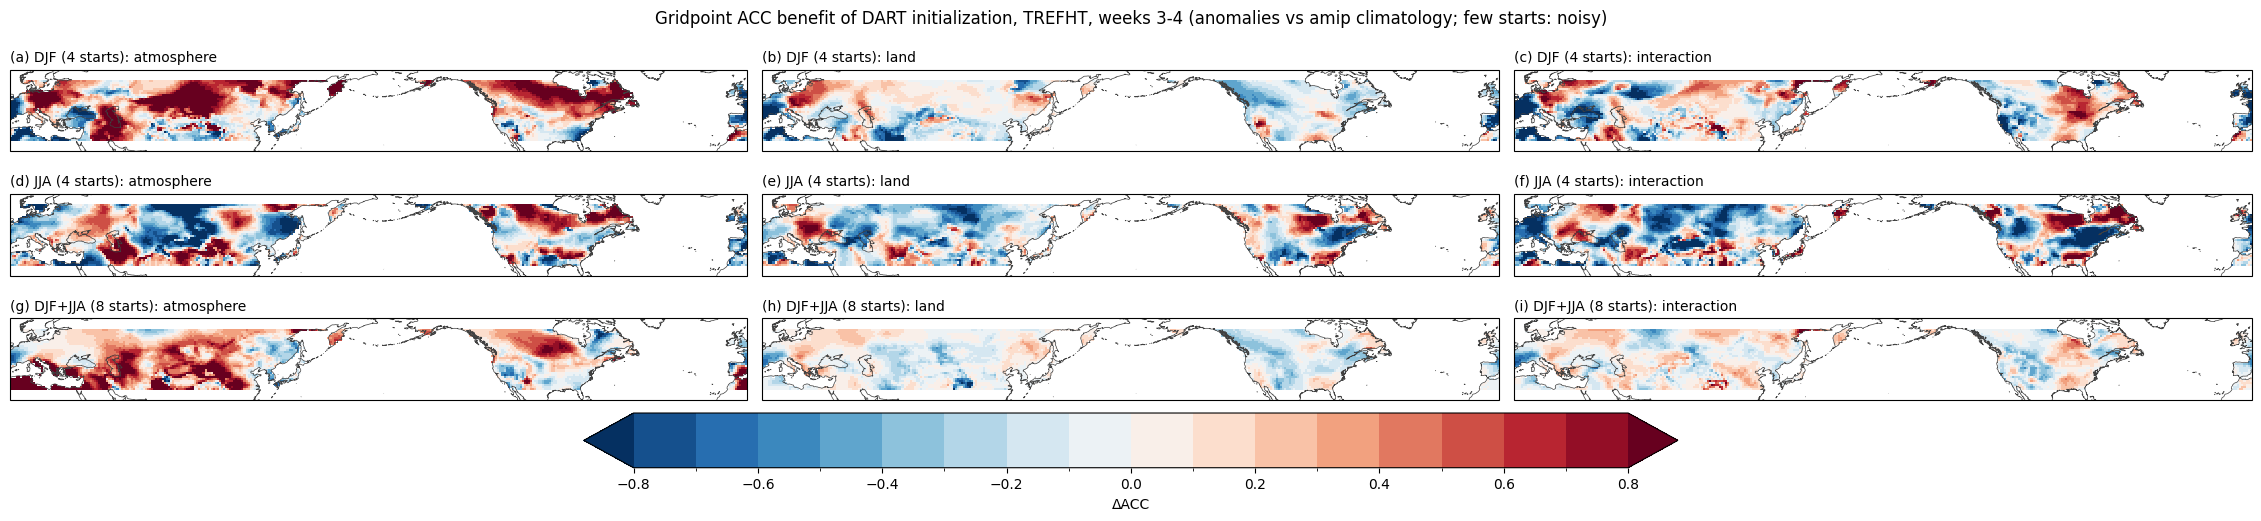

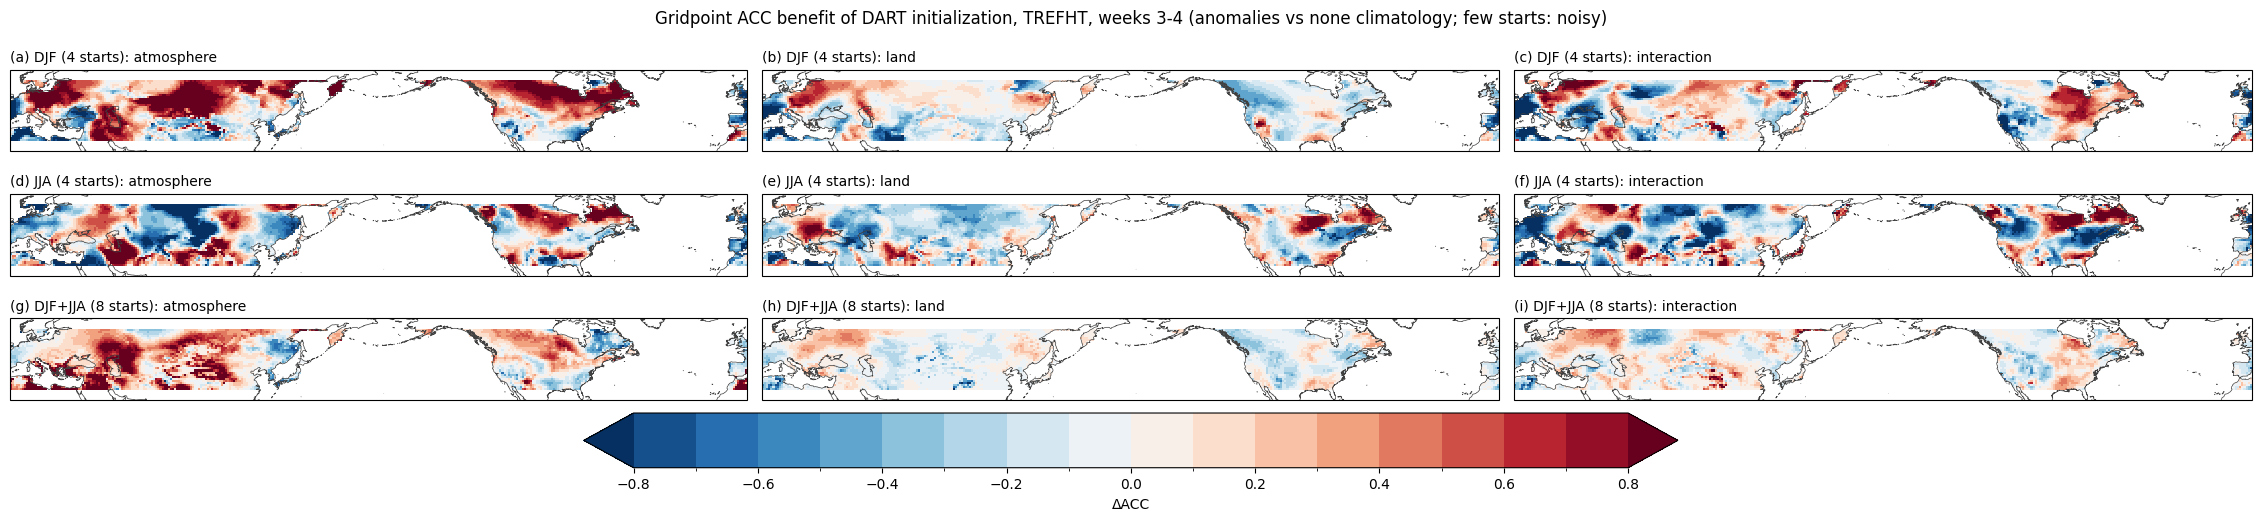

In [6]:
# ============================ Figure settings: edit here and rerun this cell ============================
SHOW = True          # False: save the figures without showing them
FIGURE_DPI = 200
FONT_SIZE = 18       # base font size (pt); every label of every figure scales with it
FONT_SCALES = dict(label=1.0, title=1.0, tick=0.9, legend=1.0, suptitle=1.15, cell=0.75)  # x FONT_SIZE

from util.fcst_init_plotting import set_font_size
set_font_size(FONT_SIZE, **FONT_SCALES)
save = figure_saver(case.figure_dir, dpi=FIGURE_DPI, show=SHOW)
# =========================================================================================================

from util.fcst_init_plotting import plot_map_grid
from util.init_benefit import week_index

names = [n for n in ("atmosphere", "land", "interaction") if n in cfg.contrasts]
idx = week_index(case.weeks, cfg.map_weeks)
lat0, lat1 = cfg.region["lat"]
lon0, lon1 = cfg.region["lon"]
extent = (-180.0, 179.99, max(lat0 - 5, -90), min(lat1 + 5, 90))   # the region's band (data exist only there)
if lon1 - lon0 < 360:
    extent = (lon0 - 5, lon1 + 5, *extent[2:])
width = 7.5
size = (width, width * (extent[3] - extent[2]) / (extent[1] - extent[0]) + 0.6)
weeks = f"weeks {cfg.map_weeks[0]}-{cfg.map_weeks[-1]}"
for b in cfg.biases:
    panels = {}
    for name, set_seasons in case.sets.items():                  # rows: each season, then all seasons
        ds = maps[b, name]
        m = ds.isel(week=idx).mean("week")
        row = f"{'+'.join(set_seasons)} ({ds.attrs['n_starts']} starts)"
        panels[row] = {k: m[k] for k in names if k in m}
    save(plot_map_grid(panels, title=f"Gridpoint ACC benefit of DART initialization, {cfg.variable}, {weeks} "
                                     f"(anomalies vs {b} climatology; few starts: noisy)",
                       levels=np.linspace(-0.8, 0.8, 17), label="ΔACC", extent=extent, panel_size=size),
         f"init_benefit_map_{b}.png")